
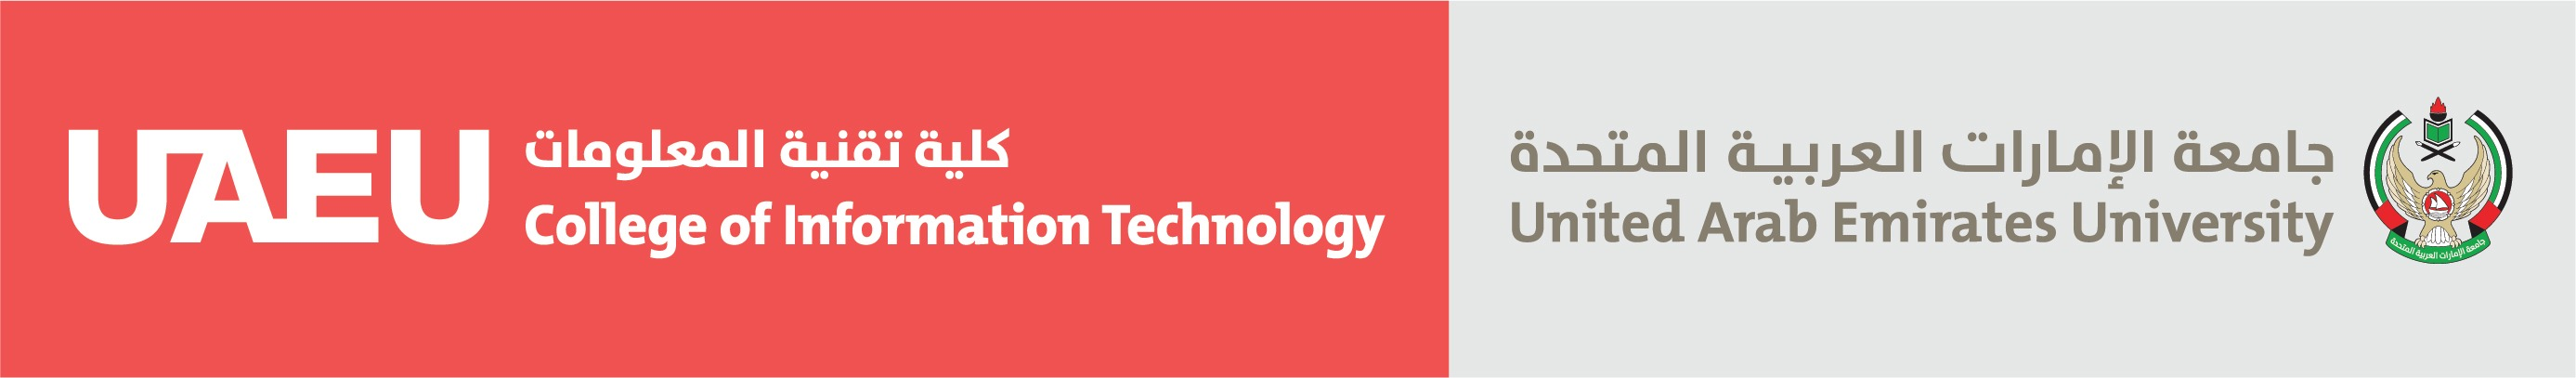

In [209]:
from pathlib import Path
from IPython.display import HTML, display
import base64

logo_path = Path("assets/CIT_Logo.jpg")
logo_url = "https://raw.githubusercontent.com/SaeedAlbarhami/CSPG730-IMDB-EDA/HEAD/assets/CIT_Logo.jpg"
logo_src = logo_url if not logo_path.is_file() else "data:image/jpeg;base64," + base64.b64encode(logo_path.read_bytes()).decode()
display(HTML(f'<img src="{logo_src}" alt="UAEU College of Information Technology" width="1000" style="display:block; width:1000px; max-width:100%; height:auto; margin:16px auto;">'))

<div style="max-width:760px; margin:16px auto 32px; padding:28px 24px; box-sizing:border-box; text-align:center; font-family:Arial,sans-serif; line-height:1.6; color:#1f2937; background:#f8fafc; border:1px solid #e2e8f0; border-top:4px solid #c62828; border-radius:12px;">
    <div style="font-size:22px; font-weight:700;">United Arab Emirates University</div>
    <div style="font-size:16px; color:#475569;">College of Information Technology</div>
    <div style="margin-top:20px; font-size:16px; font-weight:600;">CSPG730: Data Mining for Advanced Analytics</div>
    <div style="margin-top:8px; font-size:20px; font-weight:700;">Assignment 1</div>
    <div style="font-size:17px;">Exploratory Data Analysis and Knowledge Discovery</div>
    <div style="margin-top:14px; font-size:14px; color:#475569;">Fall 2026 &nbsp; &bull; &nbsp; Due: October 22, 2026</div>
    <div style="margin-top:20px; padding-top:16px; border-top:1px solid #e2e8f0; font-size:15px;">
        <strong>Saeed Thabit</strong><br>
        Student ID: 700049326
    </div>
</div>

### Assignment Objective
The objective of this assignment is to apply data mining and statistical analysis techniques to explore a real-world dataset, identify patterns and relationships, assess data quality, and extract meaningful, evidence-based insights.

### Selected Dataset: IMDB Movie Dataset

| Item | Detail |
|---|---|
| File | `data/imdb_movie_dataset.csv`|
| Size | 1,000 rows × 12 columns |
| Time span | Movies released 2006 – 2016 |
| Unit of observation | One row = one movie |
| Domain | Entertainment / film industry |

### Data Dictionary

| # | Attribute | Description | Data Type | Unit / Format |
|---|---|---|---|---|
| 1 | Rank | Position of the movie in the list | int64 | Integer |
| 2 | Title | Movie title | object | Text |
| 3 | Genre | Genre(s) of the movie | object | Comma-separated text |
| 4 | Description | Short plot summary | object | Free text |
| 5 | Director | Director of the movie | object | Text |
| 6 | Actors | Main cast members | object | Comma-separated text |
| 7 | Year | Release year | int64 | YYYY |
| 8 | Runtime (Minutes) | Duration of the movie | int64 | Minutes |
| 9 | Rating | Average IMDB user rating | float64 | Score 1 – 10, one decimal |
| 10 | Votes | Number of IMDB user votes | int64 | Count |
| 11 | Revenue (Millions) | Box-office revenue | float64 | Millions (currency not stated, assumed USD) |
| 12 | Metascore | Critics' score from Metacritic | float64 | Score 0 – 100 |

### Environment Setup
• Libraries used: pandas, numpy, matplotlib, seaborn, scipy, scikit-learn

• Data tracking: Raw data preserved in df_raw unchanged.


In [210]:
from pathlib import Path
import pandas as pd             
import numpy as np                 
import matplotlib.pyplot as plt   
import seaborn as sns              
from scipy import stats
from sklearn.preprocessing import MinMaxScaler, StandardScaler

sns.set_theme(style="whitegrid")             
pd.set_option("display.max_columns", None)   
DATA_DIR = Path("data")
RAW_DATA = DATA_DIR / "imdb_movie_dataset.csv"
CLEANED_DATA = DATA_DIR / "imdb_cleaned.csv"

# Prefer the local CSV or read it from the GitHub default branch if no local file.
GITHUB_DATA = "https://raw.githubusercontent.com/SaeedAlbarhami/CSPG730-IMDB-EDA/HEAD/data/imdb_movie_dataset.csv"
DATA_DIR.mkdir(parents=True, exist_ok=True)
df_raw = pd.read_csv(RAW_DATA if RAW_DATA.is_file() else GITHUB_DATA)

---
## Task 1: Dataset Understanding and Profiling (5 Marks)
Perform a comprehensive examination of the assigned dataset.

1. Explain the dataset's purpose, domain, and potential analytical applications.
2. Identify the number of records, attributes, data types, and unit of observation.
3. Classify attributes as numerical, categorical, ordinal, temporal, or other relevant types.
4. Identify missing values, duplicate records, inconsistent formats, and potential data quality issues.
5. Examine attribute distributions and summarize the dataset's important characteristics.
6. Discuss the limitations of the dataset and any assumptions required for analysis.

**Expected outcome:** A dataset profile supported by summary tables and appropriate visualizations.

### Solution – Task 1

#### 1.1 Explain the dataset's purpose, domain, and potential analytical applications.

**Purpose:** to record the identity, content, people, and reception of 1,000 movies in the supplied sample released between 2006 and 2016.

**Domain:** entertainment and film industry.

**Potential Analytical applications:**

1. Finding which factors (genre, runtime, director) are linked to high ratings.
2. Comparing audience opinion (IMDB Rating) with critic opinion (Metascore).
3. Studying how popularity (Votes) relates to commercial success (Revenue).
4. Comparing genres by quality and by box-office performance.
5. Tracking how ratings and popularity change across release years.

#### 1.2 Identify the number of records, attributes, data types, and unit of observation.

In [211]:
df_raw.head()

,Rank,Title,Genre,Description,Director,Actors,Year,Runtime (Minutes),Rating,Votes,Revenue (Millions),Metascore
0,1,Guardians of the Galaxy,"Action,Adventure,Sci-Fi",A group of intergalactic criminals are forced ...,James Gunn,"Chris Pratt, Vin Diesel, Bradley Cooper, Zoe S...",2014,121,8.1,757074,333.13,76.0
1,2,Prometheus,"Adventure,Mystery,Sci-Fi","Following clues to the origin of mankind, a te...",Ridley Scott,"Noomi Rapace, Logan Marshall-Green, Michael Fa...",2012,124,7.0,485820,126.46,65.0
2,3,Split,"Horror,Thriller",Three girls are kidnapped by a man with a diag...,M. Night Shyamalan,"James McAvoy, Anya Taylor-Joy, Haley Lu Richar...",2016,117,7.3,157606,138.12,62.0
3,4,Sing,"Animation,Comedy,Family","In a city of humanoid animals, a hustling thea...",Christophe Lourdelet,"Matthew McConaughey,Reese Witherspoon, Seth Ma...",2016,108,7.2,60545,270.32,59.0
4,5,Suicide Squad,"Action,Adventure,Fantasy",A secret government agency recruits some of th...,David Ayer,"Will Smith, Jared Leto, Margot Robbie, Viola D...",2016,123,6.2,393727,325.02,40.0


In [212]:
print("Number of records   :", df_raw.shape[0])
print("Number of attributes:", df_raw.shape[1])
print("\nData types:")
print(df_raw.dtypes)

Number of records   : 1000
Number of attributes: 12

Data types:
Rank                    int64
Title                  object
Genre                  object
Description            object
Director               object
Actors                 object
Year                    int64
Runtime (Minutes)       int64
Rating                float64
Votes                   int64
Revenue (Millions)    float64
Metascore             float64
dtype: object


| Item | Result |
|---|---|
| Records | 1,000 |
| Attributes | 12 |
| Data types | 4 × `int64`, 3 × `float64`, 5 × `object` (text) |
| Unit of observation | One movie |

`Metascore` holds whole numbers but is stored as `float64` because of missing values (NaN). After imputation, it is converted to integer in 2.5.

#### 1.3 Classify attributes as numerical, categorical, ordinal, temporal, or other relevant types.

| Attribute | Category | Measurement Scale | Discrete / Continuous | Reason |
|---|---|---|---|---|
| Rank | Categorical | Ordinal | Discrete | Order matters |
| Title | Categorical | Nominal | Discrete | A name or identifier with no order |
| Genre | Categorical | Nominal (multi-valued) | Discrete | 1 – 3 labels per movie, no order |
| Description | Text | Nominal (free text) | – | Unstructured text |
| Director | Categorical | Nominal | Discrete | A name label |
| Actors | Categorical | Nominal (multi-valued) | Discrete | A list of 3 – 4 names |
| Year | Temporal | Interval | Discrete | Equal gaps between years, but no true zero |
| Runtime (Minutes) | Numerical | Ratio | Continuous | True zero, 120 min is twice 60 min |
| Rating | Numerical | Interval | Discrete | Average of user scores on a 1 – 10 scale |
| Votes | Numerical | Ratio | Discrete | A count with a true zero |
| Revenue (Millions) | Numerical | Ratio | Continuous | Money with a true zero |
| Metascore | Numerical | Interval | Discrete | Whole-number score from 0 – 100 |


#### 1.4 Identify missing values, duplicate records, inconsistent formats, and potential data quality issues.

##### 1.4.1 Missing values

In [213]:
missing = pd.DataFrame({
    "Missing Count": df_raw.isnull().sum(),
    "Missing %": (df_raw.isnull().mean() * 100).round(1),
})
missing[missing["Missing Count"] > 0]

,Missing Count,Missing %
Revenue (Millions),128,12.8
Metascore,64,6.4


Only two columns have gaps: **Revenue (Millions)** (128, 12.8%) and **Metascore** (64, 6.4%). The other 10 columns are complete.

##### 1.4.2 Duplicate records
We check two levels: full rows that repeat, and titles that repeat.

In [214]:
print("Duplicate full rows:", df_raw.duplicated().sum())
print("Duplicate titles   :", df_raw["Title"].duplicated().sum())

# Show every row whose title appears more than once
df_raw[df_raw["Title"].duplicated(keep=False)][["Rank", "Title", "Year", "Director", "Genre", "Rating", "Votes"]]

Duplicate full rows: 0
Duplicate titles   : 1


,Rank,Title,Year,Director,Genre,Rating,Votes
239,240,The Host,2013,Andrew Niccol,"Action,Adventure,Romance",5.9,96852
632,633,The Host,2006,Bong Joon Ho,"Comedy,Drama,Horror",7.0,73491


There are no duplicate rows, but the title **"The Host"** appears twice. The two rows differ in year, director, genre, rating, and votes, so this needs a closer look in 2.2.

##### 1.4.3 Inconsistent formats
We check the text columns for extra spaces and inconsistent separators, and check how multi-valued columns are stored.

In [215]:
for col in ["Title", "Genre", "Director", "Actors"]:
    print(f"Extra spaces in {col:<8}:", (df_raw[col] != df_raw[col].str.strip()).sum())

print("\nGenre  values using ', ' (comma + space):", df_raw["Genre"].str.contains(", ").sum())
print("Actors values with a comma NOT followed by a space:", df_raw["Actors"].str.contains(r",\S").sum())
print("Example:", df_raw.loc[3, "Actors"])

print("\nGenres per movie:")
print(df_raw["Genre"].str.split(",").str.len().value_counts().sort_index())

Extra spaces in Title   : 0
Extra spaces in Genre   : 0
Extra spaces in Director: 0
Extra spaces in Actors  : 0

Genre  values using ', ' (comma + space): 0
Actors values with a comma NOT followed by a space: 349
Example: Matthew McConaughey,Reese Witherspoon, Seth MacFarlane, Scarlett Johansson

Genres per movie:
Genre
1    105
2    235
3    660
Name: count, dtype: int64


- **Actors** uses two separator styles: 349 rows contain at least one comma without a following space (e.g. `Matthew McConaughey,Reese Witherspoon, ...`). This is an inconsistent format.

- **Genre** consistently uses `","` with no space. It is multi-valued: 105 movies have 1 genre, 235 have 2, and 660 have 3.
- No values have leading or trailing spaces.
- Two column names contain spaces and units: `Runtime (Minutes)` and `Revenue (Millions)`.

##### 1.4.4 Other potential data quality issues

In [216]:
# outside of valid range
print("Rating outside 1-10    :", ((df_raw["Rating"] < 1) | (df_raw["Rating"] > 10)).sum())
print("Metascore outside 0-100:", ((df_raw["Metascore"] < 0) | (df_raw["Metascore"] > 100)).sum())
print("Checked for impossible negative values: runtime , votes , revenue:",
      (df_raw[["Runtime (Minutes)", "Votes", "Revenue (Millions)"]] < 0).sum().sum())

# Suspcius zero revenue
df_raw[df_raw["Revenue (Millions)"] == 0][["Title", "Year", "Votes", "Revenue (Millions)"]]

Rating outside 1-10    : 0
Metascore outside 0-100: 0
Checked for impossible negative values: runtime , votes , revenue: 0


,Title,Year,Votes,Revenue (Millions)
231,A Kind of Murder,2016,3305,0.0


No violations were found in the numeric range checks above. These checks do not verify the accuracy of each record. One movie, *A Kind of Murder*, has **Revenue = 0.00** and only 3,305 votes.

**Summary of data quality issues found:**

| # | Issue | Evidence | Handled in |
|---|---|---|---|
| 1 | Missing values | Revenue 128 (12.8%), Metascore 64 (6.4%) | 2.1 |
| 2 | Repeated title | "The Host" appears twice | 2.2.1 |
| 3 | Inconsistent separators | 349 Actors values contain a comma without a space | 2.2.2 |
| 4 | Suspicious value | Revenue = 0.00 for *A Kind of Murder* | 2.2.3 |
| 5 | Skew and extreme values | Votes and Revenue are strongly right-skewed (see 1.5) | 2.3, 2.4 |
| 6 | Column names with spaces/units | `Runtime (Minutes)`, `Revenue (Millions)` | 2.5.1 |
| 7 | Optional type conversion | Metascore stored as float to support missing values | 2.5.1 |
| 8 | Multi-valued attributes | Genre (1 – 3 values), Actors (3 – 4 values) | 2.5.2 |
| 9 | Unbalanced years | 2016 has 297 movies (29.7%) | Limitation (1.6) |

#### 1.5 Examine attribute distributions and summarize the dataset's important characteristics.

##### 1.5.1 Summary tables

In [217]:
df_raw.describe().round(2)

,Rank,Year,Runtime (Minutes),Rating,Votes,Revenue (Millions),Metascore
count,1000.00,1000.00,1000.00,1000.00,1000.00,872.00,936.00
mean,500.50,2012.78,113.17,6.72,169808.26,82.96,58.99
std,288.82,3.21,18.81,0.95,188762.65,103.25,17.19
min,1.00,2006.00,66.00,1.90,61.00,0.00,11.00
25%,250.75,2010.00,100.00,6.20,36309.00,13.27,47.00
50%,500.50,2014.00,111.00,6.80,110799.00,47.98,59.50
75%,750.25,2016.00,123.00,7.40,239909.75,113.72,72.00
max,1000.00,2016.00,191.00,9.00,1791916.00,936.63,100.00


In [218]:
df_raw.describe(include="object")

,Title,Genre,Description,Director,Actors
count,1000,1000,1000,1000,1000
unique,999,207,1000,644,996
top,The Host,"Action,Adventure,Sci-Fi",A group of intergalactic criminals are forced ...,Ridley Scott,"Jennifer Lawrence, Josh Hutcherson, Liam Hemsw..."
freq,2,50,1,8,2


- **Year** covers only 2006 – 2016, with a median of 2014, so the sample is concentrated toward the end of its 2006–2016 coverage.

- **Rating** averages 6.72 (range 1.9 – 9.0). **Metascore** averages 58.99 (range 11 – 100).

- **Votes** and **Revenue** have a mean far above the median (Revenue: 82.96 vs 47.98). This shows **right skew**: a few blockbusters raise the mean.

- **Director** has 644 unique values for 1,000 movies, indicating many distinct directors.

##### 1.5.2 Distribution plots

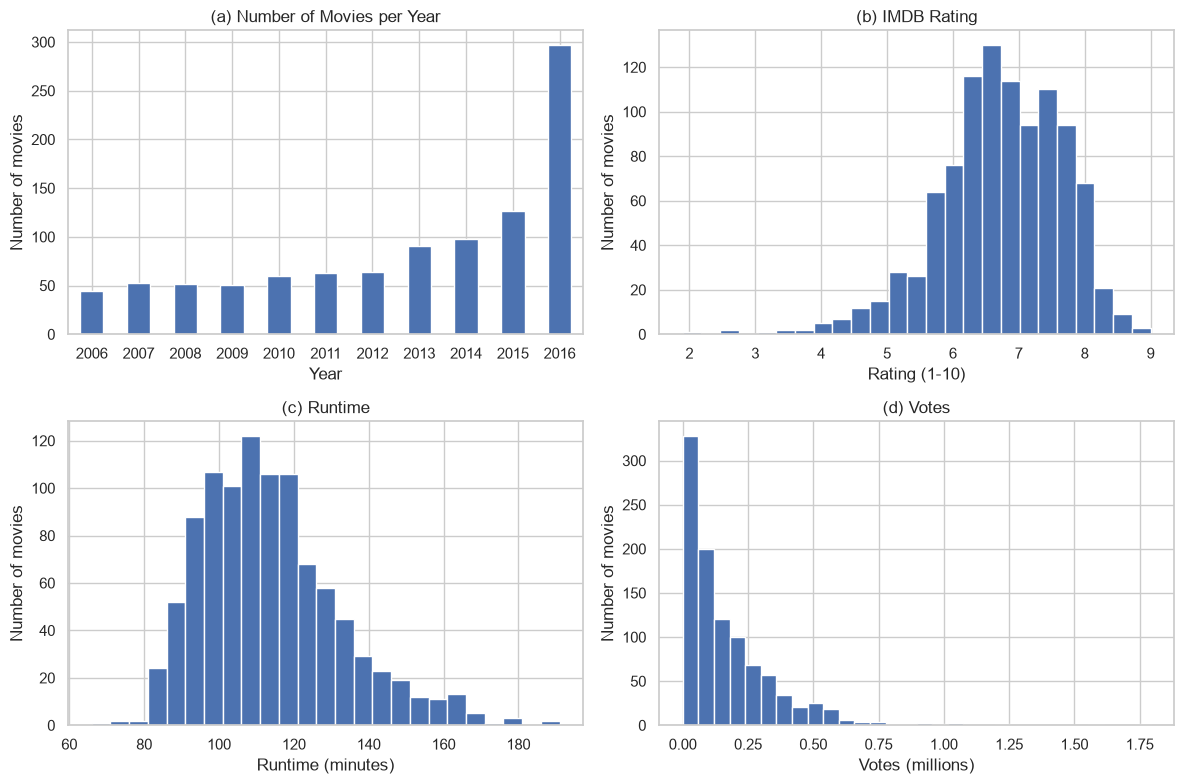

In [219]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

df_raw["Year"].value_counts().sort_index().plot(kind="bar", ax=axes[0, 0], rot=0)
axes[0, 0].set(title="(a) Number of Movies per Year", xlabel="Year", ylabel="Number of movies")

axes[0, 1].hist(df_raw["Rating"], bins=25, edgecolor="white")
axes[0, 1].set(title="(b) IMDB Rating", xlabel="Rating (1-10)", ylabel="Number of movies")

axes[1, 0].hist(df_raw["Runtime (Minutes)"], bins=25, edgecolor="white")
axes[1, 0].set(title="(c) Runtime", xlabel="Runtime (minutes)", ylabel="Number of movies")

axes[1, 1].hist(df_raw["Votes"] / 1e6, bins=30, edgecolor="white")
axes[1, 1].set(title="(d) Votes", xlabel="Votes (millions)", ylabel="Number of movies")

plt.tight_layout()
plt.show()

- **(a)** The data is weighted toward recent years. 2016 alone has **297 movies** (29.7%), compared with 44 in 2006.

- **(b)** Ratings cluster around 6.5 – 7.5, with a longer tail toward low scores (**left skew**).

- **(c)** Most movies run 90 – 130 minutes, with a tail of long films.

- **(d)** Votes are **strongly right-skewed**. Most movies have under 0.25 million votes, and a few exceed 1 million.

#### 1.6 Discuss the limitations of the dataset and any assumptions required for analysis.

**Limitations:**

1. **Sample, not population:** 1,000 selected movies with an undocumented sampling method, so results cannot be assumed to represent all films.
2. **Unbalanced years:** 2016 has 29.7% of all movies.
3. **Missing revenue** for 12.8% of movies, mostly 2016 releases (shown in 2.1).
4. **Revenue is not inflation-adjusted**, and its currency is not stated.
5. **Votes depend on time:** release year may affect time available to collect votes, but the collection date is unknown.
6. **Multi-valued text** (Genre, Actors) must be split before analysis.
7. **No budget column**, so profitability cannot be measured.

**Assumptions:**

1. Each row is a distinct movie (verified in 2.2.1).
2. Revenue is in millions of US dollars.
3. Rating, Votes, and Metascore were collected at the same point in time.
4. The first genre is retained as `First_Genre` for convenience, its position does not establish importance. Genre comparisons use all listed labels.

---
## Task 2: Data Cleaning and Preparation (10 Marks)
Identify and address data quality problems using appropriate preprocessing techniques.

1. Investigate missing data patterns and justify the chosen treatment methods.
2. Detect duplicate or inconsistent records and determine whether they should be corrected or removed.
3. Identify potential outliers using statistical methods such as IQR and Z-scores.
4. Investigate whether detected outliers represent errors or valid extreme observations.
5. Perform necessary data type corrections, transformations, and normalization where appropriate.
6. Compare dataset characteristics before and after cleaning.

**Expected outcome:** A cleaned dataset and a documented explanation of all modifications.

### Solution – Task 2
All cleaning is done on a copy, `df`, so `df_raw` stays unchanged for the before/after comparison in 2.6.

In [220]:
df = df_raw.copy()

#### 2.1 Investigate missing data patterns and justify the chosen treatment methods.

##### 2.1.1 Missing data patterns
First we check whether the two columns tend to be missing together, and whether missingness depends on the release year.

In [221]:
rev_missing = df["Revenue (Millions)"].isnull()
meta_missing = df["Metascore"].isnull()

print("Revenue missing only  :", (rev_missing & ~meta_missing).sum())
print("Metascore missing only:", (~rev_missing & meta_missing).sum())
print("Both missing          :", (rev_missing & meta_missing).sum())
print("Rows with any missing :", (rev_missing | meta_missing).sum())

Revenue missing only  : 98
Metascore missing only: 34
Both missing          : 30
Rows with any missing : 162


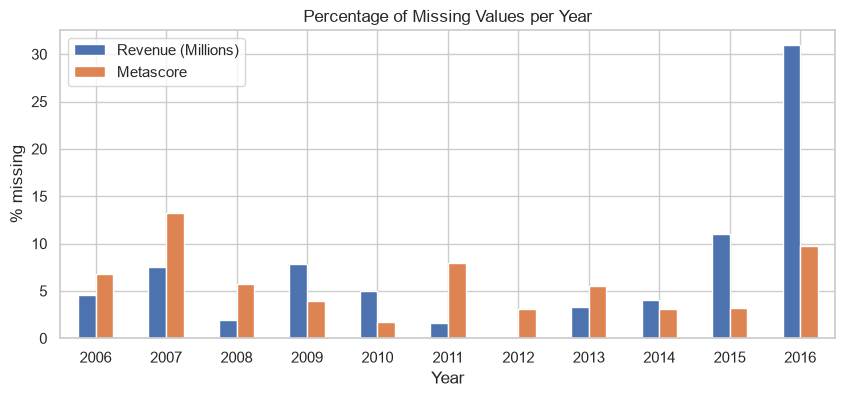

In [222]:
# Percentage missing per release year
missing_by_year = df.groupby("Year")[["Revenue (Millions)", "Metascore"]].apply(lambda g: g.isnull().mean() * 100)

ax = missing_by_year.plot(kind="bar", figsize=(10, 4), rot=0)
ax.set(title="Percentage of Missing Values per Year", xlabel="Year", ylabel="% missing")
plt.show()

In [223]:
# are movies without revenue different from movies with revenue?
profile = df.groupby(rev_missing)[["Rating", "Votes"]].median()
profile.index = ["Revenue present", "Revenue missing"]
profile

,Rating,Votes
Revenue present,6.90,134654.0
Revenue missing,6.15,4741.5


**Findings:**

1. 162 movies (16.2%) have at least one missing value, and only 30 are missing both.
2. Revenue is missing for **31% of 2016 movies**, compared with under 11% in every other year. Incomplete reporting at collection time is one possible explanation, the dataset does not record the reason.
3. Movies without revenue have a median of **~4.7k votes**, compared with ~135k for the others, indicating lower recorded voting activity, without establishing release size or budget.

Missingness is associated with observed year and voting activity, making a completely random missingness assumption questionable; the underlying mechanism cannot be established from these comparisons alone.

##### 2.1.2 Treatment and justification

| Option | Decision | Plain English Justification |
| --- | --- | --- |
| **Drop rows** | Rejected | Removes 162 movies with incomplete records (16.2% of the dataset) and biases the sample toward older/heavily voted films. |
| **Fill with mean** | Rejected | A few huge blockbusters pull the average up to ~$83M, making it unrealistically high for a typical film. |
| **Fill with median** | **Chosen** | Provides a simple baseline value for export that isn't skewed by extreme box office hits. |
| **Add a 0/1 flag** | **Chosen** | Marks which values were filled vs. real, allowing future analysis to isolate original data. |

- The Metascore median (59.5) is rounded to 60 because Metascores are whole numbers.
  

- **Limitation:** the missing-revenue group has fewer votes, so the overall median may be inappropriate for this group. Imputation reduces variation and can distort associations. All revenue and Metascore findings in Task 3 exclude the filled values.

In [224]:
# 1) Flag the missing values before filling them (1 = was missing)
df["Revenue_Missing"] = df["Revenue (Millions)"].isnull().astype(int)
df["Metascore_Missing"] = df["Metascore"].isnull().astype(int)

# 2) Fill with the median
revenue_median = df["Revenue (Millions)"].median()
metascore_median = round(df["Metascore"].median())     # whole number, like all Metascores
df["Revenue (Millions)"] = df["Revenue (Millions)"].fillna(revenue_median)
df["Metascore"] = df["Metascore"].fillna(metascore_median)

print("Revenue median used  :", revenue_median)
print("Metascore median used:", metascore_median)
print("Missing values left  :", df[["Revenue (Millions)", "Metascore"]].isnull().sum().sum())

Revenue median used  : 47.985
Metascore median used: 60
Missing values left  : 0


##### Impact of Median Imputation on Summary Statistics

1. **Median:** Revenue stays at 47.985 million (displayed as 47.98 in the summary table); Metascore changes from 59.5 to 60 because its fill value is rounded.
2. **Mean:** Revenue decreases from 82.96 to 78.48 million; Metascore increases slightly from 58.99 to 59.05.
3. **Standard deviation:** Revenue decreases from 103.25 to 97.12 million, and Metascore from 17.19 to 16.64, because filling values near the center reduces the spread.
4. **Frequency:** The filled values become more frequent, creating an artificial concentration near the center; these values are flagged and excluded from Task 3 revenue and Metascore analyses.

#### 2.2 Detect duplicate or inconsistent records and determine whether they should be corrected or removed.

##### 2.2.1 Repeated title: "The Host"
**How it was found:** `df["Title"].duplicated().sum()` returned 1, while `df.duplicated().sum()` (full rows) returned 0. The title repeats, but the rest of the row does not.

**Evidence** (from 1.4.2):

| Attribute | Rank 240 | Rank 633 |
|---|---|---|
| Year | 2013 | 2006 |
| Director | Andrew Niccol | Bong Joon Ho |
| Genre | Action, Adventure, Romance | Comedy, Drama, Horror |
| Rating / Votes | 5.9 / 96,852 | 7.0 / 73,491 |

Every other attribute differs, so these are **two different movies that share a name**, not a duplicated record.

| Option | Decision | Reason |
|---|---|---|
| Remove one row | Rejected | It would delete a real movie |
| Add the year to the title | **Chosen** | Disambiguates the two display labels in this file, Rank remains the record identifier |

In [225]:
dup = df["Title"].duplicated(keep=False)
df.loc[dup, "Title"] = df.loc[dup, "Title"] + " (" + df.loc[dup, "Year"].astype(str) + ")"

print(df.loc[dup, ["Title", "Year", "Director"]])
print("\nDuplicate titles now:", df["Title"].duplicated().sum())

               Title  Year       Director
239  The Host (2013)  2013  Andrew Niccol
632  The Host (2006)  2006   Bong Joon Ho

Duplicate titles now: 0


##### 2.2.2 Inconsistent separators in Actors
**How it was found:** in 1.4.3, 349 Actors values contained a comma not followed by a space.

**Decision: correct the values.** The names themselves are valid, so only the separator is standardized to `", "`. Without this, `"Chris Pratt"` and `" Chris Pratt"` would count as two different actors after splitting.

In [226]:
# Replace any comma (with or without surrounding spaces) by ", "
df["Actors"] = df["Actors"].str.replace(r"\s*,\s*", ", ", regex=True)

print("Actors values with a comma NOT followed by a space:", df["Actors"].str.contains(r",\S").sum())
print("Example:", df.loc[3, "Actors"])

Actors values with a comma NOT followed by a space: 0
Example: Matthew McConaughey, Reese Witherspoon, Seth MacFarlane, Scarlett Johansson


##### 2.2.3 Revenue = 0.00 (*A Kind of Murder*)
**How it was found:** the range check in 1.4.4.

**Decision: keep the value.** Zero is inside the valid range. We cannot verify it from the data, so it is documented here rather than changed.

#### 2.3 Identify potential outliers using statistical methods such as IQR and Z-scores.

Revenue and Metascore are tested on their **real values only**, because the filled-in medians are not real observations.

##### 2.3.1 IQR method
$$IQR = Q_3 - Q_1 \qquad \text{Lower} = Q_1 - 1.5 \times IQR \qquad \text{Upper} = Q_3 + 1.5 \times IQR$$

A value below the lower bound or above the upper bound is flagged as a potential outlier, the rule alone does not identify an error.

In [227]:
def iqr_outliers(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return q1, q3, iqr, lower, upper, series[(series < lower) | (series > upper)]

columns_to_check = {
    "Runtime (Minutes)": df["Runtime (Minutes)"],
    "Rating": df["Rating"],
    "Votes": df["Votes"],
    "Revenue (Millions)": df.loc[df["Revenue_Missing"] == 0, "Revenue (Millions)"],
    "Metascore": df.loc[df["Metascore_Missing"] == 0, "Metascore"],
}

rows = []
for name, values in columns_to_check.items():
    q1, q3, iqr, lower, upper, outliers = iqr_outliers(values)
    rows.append([name, q1, q3, iqr, lower, upper, len(outliers)])

outlier_summary = pd.DataFrame(rows, columns=["Column", "Q1", "Q3", "IQR", "Lower Bound", "Upper Bound", "# Outliers"]).round(2)
flagged_indices = set()
for values in columns_to_check.values():
    flagged_indices.update(iqr_outliers(values)[5].index)
print("Distinct movies flagged:", len(flagged_indices))
outlier_summary

Distinct movies flagged: 121


,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,# Outliers
0,Runtime (Minutes),100.00,123.00,23.00,65.50,157.50,30
1,Rating,6.20,7.40,1.20,4.40,9.20,19
2,Votes,36309.00,239909.75,203600.75,-269092.12,545310.88,45
3,Revenue (Millions),13.27,113.72,100.44,-137.40,264.38,55
4,Metascore,47.00,72.00,25.00,9.50,109.50,0


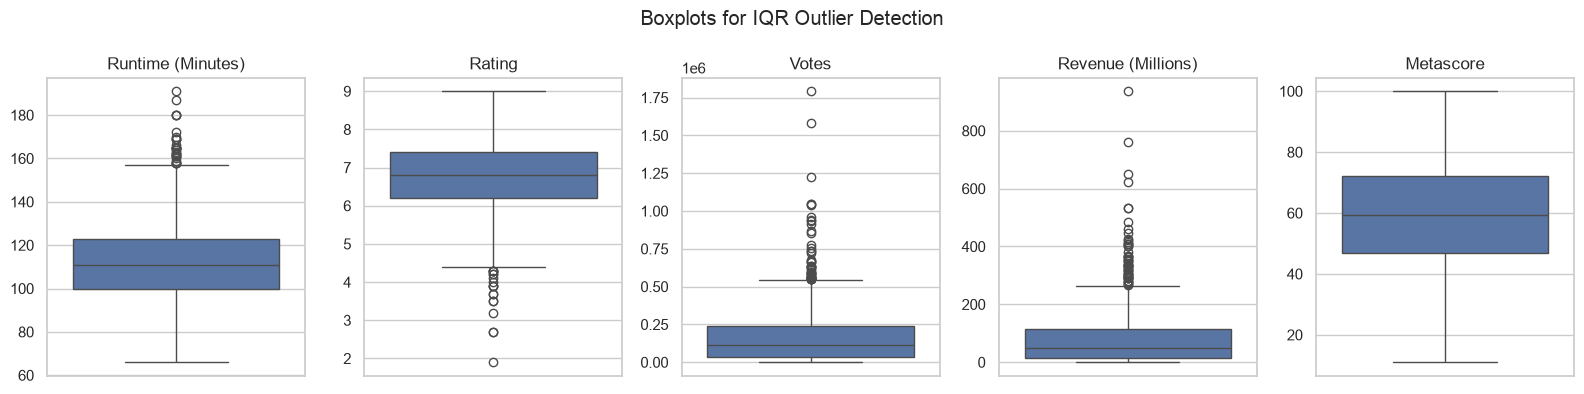

In [228]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, (name, values) in zip(axes, columns_to_check.items()):
    sns.boxplot(y=values, ax=ax)
    ax.set(title=name, ylabel="")
plt.suptitle("Boxplots for IQR Outlier Detection")
plt.tight_layout()
plt.show()

- Outliers: **Runtime 30**, **Rating 19**, **Votes 45**, **Revenue 55**, **Metascore 0**. These are **149 flagged values across 121 distinct movies**, because some movies are flagged in more than one column.
- All Runtime outliers are **long** movies. The shortest movie (66 min) is just above the lower bound (65.5).
- All Rating outliers are **low** ratings, below 4.4.
- The lower bounds for Votes and Revenue are **negative**, which is impossible. These columns are so skewed that outliers can only occur on the high side.

##### 2.3.2 Z-score method
$$z = \frac{x - \bar{x}}{s} \qquad \text{outlier if } |z| > 3$$

In [229]:
rows = []
for name, values in columns_to_check.items():
    z = pd.Series(stats.zscore(values, ddof=1), index=values.index)
    rows.append([name, len(iqr_outliers(values)[5]), (z.abs() > 3).sum()])

pd.DataFrame(rows, columns=["Column", "# IQR outliers", "# Z-score outliers (|z| > 3)"])

,Column,# IQR outliers,# Z-score outliers (|z| > 3)
0,Runtime (Minutes),30,7
1,Rating,19,8
2,Votes,45,15
3,Revenue (Millions),55,17
4,Metascore,0,0


The Z-score method flags **fewer** points: 7, 8, 15, 17, and 0. Both methods agree that Metascore has no outliers.

**Why they differ:** the Z-score uses the mean and standard deviation, which the extreme values themselves inflate. IQR uses quartiles, which are less sensitive to extreme values. Both rules can flag legitimate observations in skewed distributions, neither establishes that a value is incorrect. We use the IQR results for the decision in 2.4.

#### 2.4 Investigate whether detected outliers represent errors or valid extreme observations.
We inspect the most extreme values in each column.

In [230]:
print("Highest Revenue (Millions):")
print(df.nlargest(5, "Revenue (Millions)")[["Title", "Year", "Revenue (Millions)"]].to_string(index=False))
print("\nHighest Votes:")
print(df.nlargest(3, "Votes")[["Title", "Year", "Votes"]].to_string(index=False))
print("\nLowest Ratings:")
print(df.nsmallest(3, "Rating")[["Title", "Year", "Rating"]].to_string(index=False))
print("\nLongest Runtimes:")
print(df.nlargest(3, "Runtime (Minutes)")[["Title", "Year", "Runtime (Minutes)"]].to_string(index=False))

Highest Revenue (Millions):
                                     Title  Year  Revenue (Millions)
Star Wars: Episode VII - The Force Awakens  2015              936.63
                                    Avatar  2009              760.51
                            Jurassic World  2015              652.18
                              The Avengers  2012              623.28
                           The Dark Knight  2008              533.32

Highest Votes:
                Title  Year   Votes
      The Dark Knight  2008 1791916
            Inception  2010 1583625
The Dark Knight Rises  2012 1222645

Lowest Ratings:
                  Title  Year  Rating
         Disaster Movie  2008     1.9
Don't Fuck in the Woods  2016     2.7
   Dragonball Evolution  2009     2.7

Longest Runtimes:
                  Title  Year  Runtime (Minutes)
             Grindhouse  2007                191
      The Hateful Eight  2015                187
The Wolf of Wall Street  2013                180


**Assessment of the displayed extremes:**

| Column | Most extreme value | Assessment from this file |
|---|---|---|
| Revenue | *Star Wars: Episode VII*: 936.63M | Nonnegative and extreme, cannot verify currency or market coverage from this file |
| Votes | *The Dark Knight*: 1,791,916 | A positive integer count, plausible but not independently verified |
| Rating | *Disaster Movie*: 1.9 | Within the stated 1–10 scale |
| Runtime | *Grindhouse*: 191 min | Unusually long, but no contradictory evidence in the file |

**Decision: retain all flagged observations.** The displayed extremes pass the relevant range checks, and no evidence here justifies deleting or capping them. 

#### 2.5 Perform necessary data type corrections, transformations, and normalization where appropriate.

##### 2.5.1 Data type corrections

| Change | Reason |
|---|---|
| Rename `Runtime (Minutes)` → `Runtime_Minutes`, `Revenue (Millions)` → `Revenue_Millions` | Spaces and brackets make names awkward to use in code |
| Metascore: float → int | Scores are whole numbers, it was float only because of the missing values |
| Year kept as int | Only the year is available (no month or day), so `datetime` adds nothing |

In [231]:
df = df.rename(columns={"Runtime (Minutes)": "Runtime_Minutes", "Revenue (Millions)": "Revenue_Millions"})
df["Metascore"] = df["Metascore"].astype(int)

##### 2.5.2 Transformations

| New column | How | Reason |
|---|---|---|
| `First_Genre` (category) | First genre in the list | Convenient first-listed label, not a verified primary genre, all labels are used in Task 3 |
| `Num_Genres` | Number of genres | Counts labels, does not preserve their identities by itself, so the original Genre column is retained |
| `Revenue_Log` | $\ln(1 + \text{Revenue})$ | Reduces the strong right skew, `log1p` also handles the 0.00 value |

In [232]:
df["First_Genre"] = df["Genre"].str.split(",").str[0].astype("category")
df["Num_Genres"] = df["Genre"].str.split(",").str.len()
df["Revenue_Log"] = np.log1p(df["Revenue_Millions"])

print("Revenue skewness before log:", round(df.loc[df["Revenue_Missing"] == 0, "Revenue_Millions"].skew(), 2))
print("Revenue skewness after log :", round(df.loc[df["Revenue_Missing"] == 0, "Revenue_Log"].skew(), 2))
print()
print(df.dtypes)

Revenue skewness before log: 2.59
Revenue skewness after log : -0.68

Rank                    int64
Title                  object
Genre                  object
Description            object
Director               object
Actors                 object
Year                    int64
Runtime_Minutes         int64
Rating                float64
Votes                   int64
Revenue_Millions      float64
Metascore               int64
Revenue_Missing         int64
Metascore_Missing       int64
First_Genre          category
Num_Genres              int64
Revenue_Log           float64
dtype: object


##### 2.5.3 Normalization
The numeric columns are on very different scales (Votes up to ~1.8 million, Rating 1 – 10). Normalization puts them on a common scale:

- **Min-Max:** $x' = \dfrac{x - \min}{\max - \min}$ → range 0 to 1 (applied to Votes, Runtime)

- **Z-score:** $z = \dfrac{x - \mu}{\sigma}$ → mean 0, standard deviation 1 (applied to Rating, Metascore)

The MinMaxScaler and Z-Score Standardization transformations generate new columns while preserving the original values. These engineered columns serve to demonstrate feature scaling, whereas the primary Exploratory Data Analysis (EDA) relies entirely on original units. Programmatically, StandardScaler calculates the population standard deviation (ddof=0), which contrasts with the sample standard deviation (ddof=1) used for Z-score outlier detection in Section 2.3.2.


In [233]:
mm_scaler = MinMaxScaler()
std_scaler = StandardScaler()

df[["Votes_MinMax", "Runtime_Minutes_MinMax"]] = mm_scaler.fit_transform(df[["Votes", "Runtime_Minutes"]])
df[["Rating_Z", "Metascore_Z"]] = std_scaler.fit_transform(df[["Rating", "Metascore"]])

scaled_cols = ["Votes_MinMax", "Runtime_Minutes_MinMax", "Rating_Z", "Metascore_Z"]
pd.DataFrame({
    "Mean": df[scaled_cols].mean(),
    "Std (ddof=0)": df[scaled_cols].std(ddof=0),
    "Min": df[scaled_cols].min(),
    "Max": df[scaled_cols].max(),
}).round(3)

,Mean,Std (ddof=0),Min,Max
Votes_MinMax,0.095,0.105,0.000,1.000
Runtime_Minutes_MinMax,0.377,0.150,0.000,1.000
Rating_Z,0.000,1.000,-5.104,2.409
Metascore_Z,0.000,1.000,-2.890,2.463


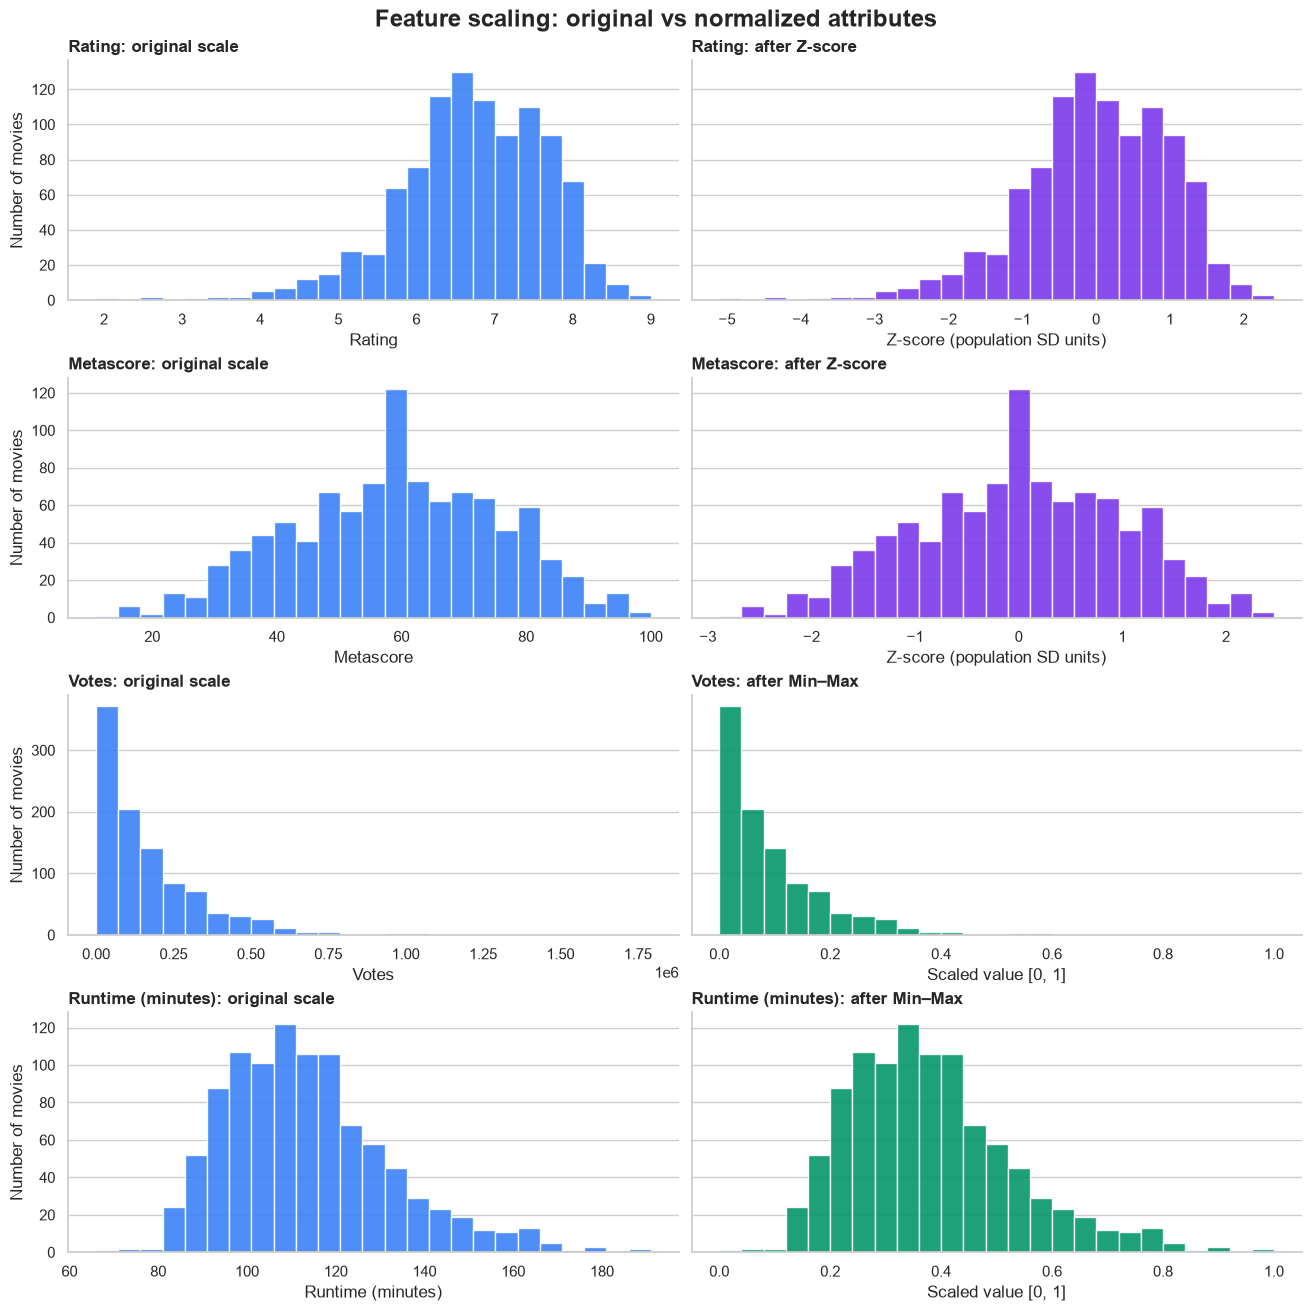

In [234]:
# Compare every normalized attribute with its original (cleaned) values.
comparisons = [
    ("Rating", "Rating_Z", "Rating", "Z-score", "#7C3AED"),
    ("Metascore", "Metascore_Z", "Metascore", "Z-score", "#7C3AED"),
    ("Votes", "Votes_MinMax", "Votes", "Min–Max", "#059669"),
    ("Runtime_Minutes", "Runtime_Minutes_MinMax", "Runtime (minutes)", "Min–Max", "#059669"),
]

fig, axes = plt.subplots(4, 2, figsize=(13, 13), sharey="row", layout="constrained")
fig.suptitle("Feature scaling: original vs normalized attributes", fontsize=17, fontweight="bold")

for row, (original, normalized, label, method, color) in enumerate(comparisons):
    # Corresponding bin edges keep the same observations in each bin.
    original_edges = np.linspace(df[original].min(), df[original].max(), 26)
    counts, _ = np.histogram(df[original], bins=original_edges)
    normalized_edges = np.linspace(df[normalized].min(), df[normalized].max(), 26)
    for col, (column, edges, bar_color) in enumerate([
        (original, original_edges, "#3B82F6"),
        (normalized, normalized_edges, color),
    ]):
        ax = axes[row, col]
        # Reuse bin counts to avoid floating-point boundary differences after scaling.
        ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge",
               color=bar_color, edgecolor="white", alpha=0.9)
        ax.set_title(f"{label}: {'original scale' if col == 0 else 'after ' + method}",
                     fontsize=12, fontweight="bold", loc="left")
        ax.set_xlabel(label if col == 0 else ("Z-score (population SD units)" if method == "Z-score" else "Scaled value [0, 1]"))
        ax.set_ylabel("Number of movies" if col == 0 else "")
        ax.grid(axis="x", visible=False)
        ax.spines[["top", "right"]].set_visible(False)
        if column == "Votes":
            ax.ticklabel_format(axis="x", style="sci", scilimits=(6, 6))

plt.show()


The Min-Max columns now range from **0 to 1**, and the Z-score columns have **mean 0 and population std 1**. Each row compares an attribute before and after its assigned scaling method, using corresponding bins and a shared count axis. The histogram shapes remain unchanged: scaling changes the units and range, not skewness or normality. The original-scale panels use the cleaned values, including the 64 imputed Metascores.

#### 2.6 Compare dataset characteristics before and after cleaning.

##### 2.6.1 Shape and missing values

In [235]:
print("Shape before:", df_raw.shape)
print("Shape after :", df.shape)

pd.DataFrame({
    "Missing Before": df_raw[["Revenue (Millions)", "Metascore"]].isnull().sum().values,
    "Missing After": df[["Revenue_Millions", "Metascore"]].isnull().sum().values,
}, index=["Revenue", "Metascore"])

Shape before: (1000, 12)
Shape after : (1000, 21)


,Missing Before,Missing After
Revenue,128,0
Metascore,64,0


The dataset still has 1,000 movies because no rows were removed, its columns increased from 12 to 21 because we added 2 missing-value flags, 3 derived attributes, and 4 scaled attributes, while the missing counts became zero after filling 128 Revenue values with the median and 64 Metascore values with the rounded median.

##### 2.6.2 Summary statistics of the imputed columns

In [236]:
pd.DataFrame({
    "Revenue Before": df_raw["Revenue (Millions)"].describe(),
    "Revenue After": df["Revenue_Millions"].describe(),
    "Metascore Before": df_raw["Metascore"].describe(),
    "Metascore After": df["Metascore"].describe(),
}).round(2)

,Revenue Before,Revenue After,Metascore Before,Metascore After
count,872.00,1000.00,936.00,1000.00
mean,82.96,78.48,58.99,59.05
std,103.25,97.12,17.19,16.64
min,0.00,0.00,11.00,11.00
25%,13.27,17.44,47.00,47.75
50%,47.98,47.98,59.50,60.00
75%,113.72,99.18,72.00,71.00
max,936.63,936.63,100.00,100.00


- **Rows:** 1,000 before and after. No movie was removed.

- **Columns:** 12 → 21, from the flags, transformations, and normalized columns.

- **Count:** Revenue 872 → 1,000, Metascore 936 → 1,000.

- **Median:** Revenue is unchanged (47.98). Metascore moves from 59.5 to 60 because of the rounding.

- **Spread:** both standard deviations shrink (Revenue 103.25 → 97.12), because many identical values were added in the middle. This is a known side effect of imputation, and another reason for keeping the flags.

##### 2.6.3 Record of preprocessing changes

| # | Step | Change | Reason |
|---|---|---|---|
| 1 | Missing values | Revenue (128) and Metascore (64) filled with the median (Metascore rounded to 60) | Skewed data, keeps all 1,000 movies |
| 2 | Binary flags | Added `Revenue_Missing`, `Metascore_Missing` | Allows analysis of real values only |
| 3 | Repeated title | "The Host" → "The Host (2013)", "The Host (2006)" | Two different movies, keep both |
| 4 | Separators | Actors separator standardized to `", "` (349 rows) | Consistent splitting of names |
| 5 | Zero revenue | *A Kind of Murder* kept at 0.00 | Valid range, cannot be verified as an error |
| 6 | Outliers | 149 flagged values across 121 movies (cross-checked with Z-score), all kept | No evidence here establishes an error |
| 7 | Renamed columns | `Runtime_Minutes`, `Revenue_Millions` | No spaces or brackets |
| 8 | Type correction | Metascore float → int, First_Genre → category | Match the nature of the data |
| 9 | Transformations | `First_Genre`, `Num_Genres`, `Revenue_Log` | Usable genre field, reduced skew |
| 10 | Normalization | Min-Max: Votes, Runtime, Z-score: Rating, Metascore | Common scale, originals kept |

##### 2.6.4 Save the cleaned dataset

In [237]:
df.to_csv(CLEANED_DATA, index=False)
print(f"Saved {CLEANED_DATA} with shape", df.shape)

Saved data/imdb_cleaned.csv with shape (1000, 21)


---
## Task 3: Exploratory Data Analysis (10 Marks)
Conduct detailed univariate, bivariate, and multivariate analysis.

1. Calculate appropriate descriptive statistics, including central tendency, dispersion, and distribution characteristics.
2. Examine the distributions of important variables.
3. Explore relationships between numerical and categorical attributes.
4. Investigate correlations and potential nonlinear relationships.
5. Identify unusual patterns, trends, or differences between meaningful subgroups.
6. Produce at least **eight informative visualizations**, using suitable chart types.

For each visualization, provide a brief interpretation explaining what it reveals and why the finding is relevant.

**Expected outcome:** A comprehensive exploratory analysis with meaningful observations rather than merely generated plots.

### Solution – Task 3
To confirm the cleaned file is reproducible, we reload it from disk. We then build `real`, a copy in which the imputed Revenue and Metascore values are set back to `NaN`. This way the Task 3 statistics and plots use **observed values only**, and pandas ignores the `NaN` values automatically.

We also build `genres`, which has one row per movie-genre pair, because a movie can belong to up to three genres.

In [238]:
movies = pd.read_csv(CLEANED_DATA)

real = movies.copy()
real.loc[real["Revenue_Missing"] == 1, ["Revenue_Millions", "Revenue_Log"]] = np.nan
real.loc[real["Metascore_Missing"] == 1, ["Metascore", "Metascore_Z"]] = np.nan

genres = real.assign(Genre=real["Genre"].str.split(",")).explode("Genre")

print("Movies:", len(real), "| real Revenue:", real["Revenue_Millions"].notna().sum(),
      "| real Metascore:", real["Metascore"].notna().sum())

Movies: 1000 | real Revenue: 872 | real Metascore: 936


#### 3.1 Calculate appropriate descriptive statistics, including central tendency, dispersion, and distribution characteristics.

- **Central tendency:** mean, median, mode (all tied modes)

- **Dispersion:** sample variance, standard deviation, IQR, min, max

- **Distribution shape:** skewness (> 0 means a long right tail) and excess kurtosis (> 0 means heavier tails than a normal distribution)

In [239]:
num = real[["Runtime_Minutes", "Rating", "Votes", "Revenue_Millions", "Metascore"]]

pd.DataFrame({
    "Mean": num.mean(), "Median": num.median(),
    "Mode(s)": [", ".join(f"{v:g}" for v in num[col].mode()) for col in num],
    "Variance": num.var(),
    "Std": num.std(), "IQR": num.quantile(0.75) - num.quantile(0.25),
    "Min": num.min(), "Max": num.max(),
    "Skewness": num.skew(), "Kurtosis": num.kurt(),
}).round(2)

,Mean,Median,Mode(s),Variance,Std,IQR,Min,Max,Skewness,Kurtosis
Runtime_Minutes,113.17,111.00,108,3.538500e+02,18.81,23.00,66.0,191.00,0.85,0.86
Rating,6.72,6.80,7.1,8.900000e-01,0.95,1.20,1.9,9.00,-0.74,1.32
Votes,169808.26,110799.00,"291, 1427, 97141",3.563134e+10,188762.65,203600.75,61.0,1791916.00,2.51,11.31
Revenue_Millions,82.96,47.98,0.03,1.066129e+04,103.25,100.44,0.0,936.63,2.59,10.61
Metascore,58.99,59.50,"66, 68, 72",2.956600e+02,17.19,25.00,11.0,100.00,-0.12,-0.61


- **Votes** (skew 2.51, kurtosis 11.31) and **Revenue** (skew 2.59, kurtosis 10.61) are heavily right-skewed with heavy tails. For these, the **median** describes a typical movie better than the mean.

- **Rating** is left-skewed (−0.74): most movies are rated reasonably well, with a tail of poorly rated films.

- **Metascore** is low in skewness (−0.12), this alone does not establish a normal distribution.

- **Runtime** is mildly right-skewed (0.85), consistent with a tail of long films.

#### 3.2 Examine the distributions of important variables.

##### Visualization 1: Distribution of IMDB Rating (Histogram + KDE)

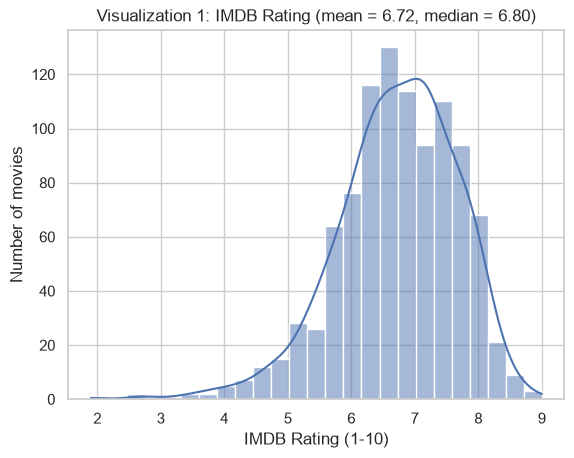

In [240]:
ax = sns.histplot(real["Rating"], bins=25, kde=True)
ax.set(title=f"Visualization 1: IMDB Rating (mean = {real['Rating'].mean():.2f}, median = {real['Rating'].median():.2f})",
       xlabel="IMDB Rating (1-10)", ylabel="Number of movies")
plt.show()

Ratings peak around 7. The mean (6.72) sits below the median (6.80) due to a trailing left tail of low-rated films.
In this sample, 7.4 represents the 75th percentile, establishing a sample-specific benchmark for highly-rated films. Because of data ties (multiple movies sharing the exact same score of 7.4), the fraction of movies scoring strictly above this benchmark may not equal exactly 25%.

##### Visualization 2: Boxplot of Runtime

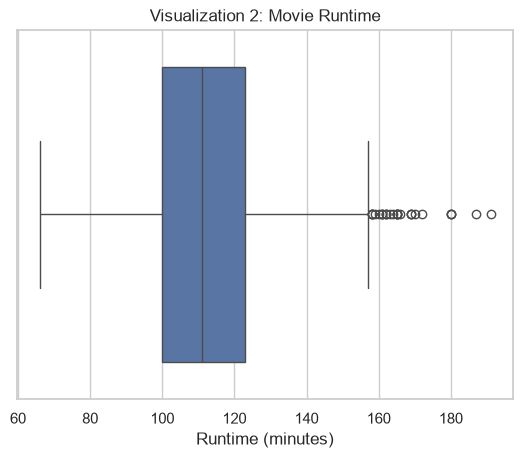

In [241]:
ax = sns.boxplot(x=real["Runtime_Minutes"])
ax.set(title="Visualization 2: Movie Runtime", xlabel="Runtime (minutes)")
plt.show()

The median runtime is 111 minutes, and half of all movies run between 100 and 123 minutes. All outliers are on the **long side**, for example *Grindhouse* at 191 minutes.
Movies cluster tightly around a two-hour format. Very long movies are rare, which makes them worth comparing on rating (see 3.4).

##### Visualization 3: Distribution of Revenue (original vs log scale)

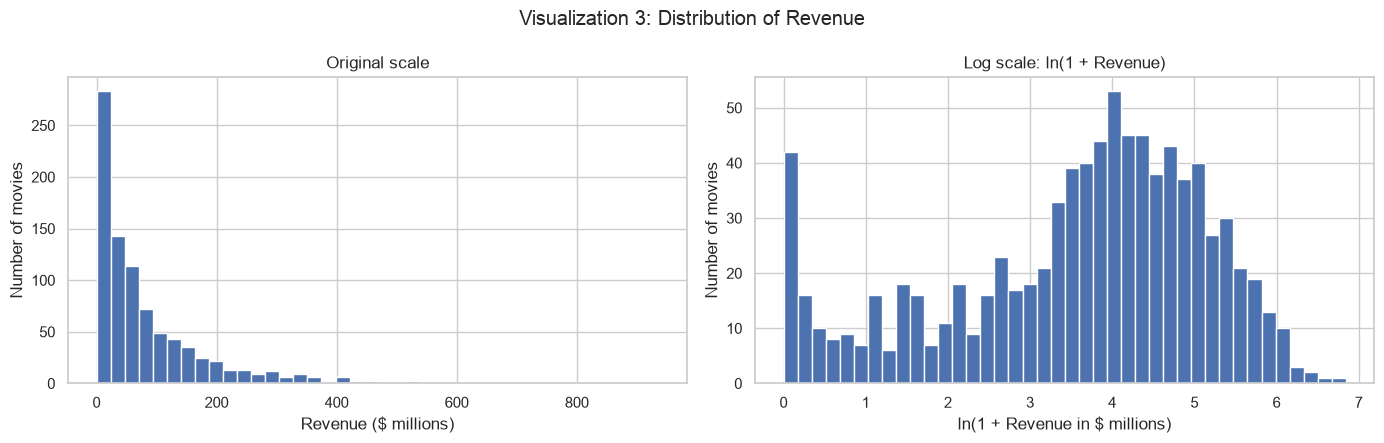

In [242]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(real["Revenue_Millions"].dropna(), bins=40, edgecolor="white")
axes[0].set(title="Original scale", xlabel="Revenue ($ millions)", ylabel="Number of movies")

axes[1].hist(real["Revenue_Log"].dropna(), bins=40, edgecolor="white")
axes[1].set(title="Log scale: ln(1 + Revenue)", xlabel="ln(1 + Revenue in $ millions)", ylabel="Number of movies")

plt.suptitle("Visualization 3: Distribution of Revenue")
plt.tight_layout()
plt.show()

On the original scale, most movies are squeezed on the left, with a long tail of blockbusters up to $937M. On the log scale, the distribution is far more balanced: skew falls from 2.59 to −0.68.
Recorded revenue varies greatly within this sample, this does not measure the whole film market. The log transformation from 2.5.2 makes it readable without deleting any extreme values.

##### Visualization 4: Top 10 Genres

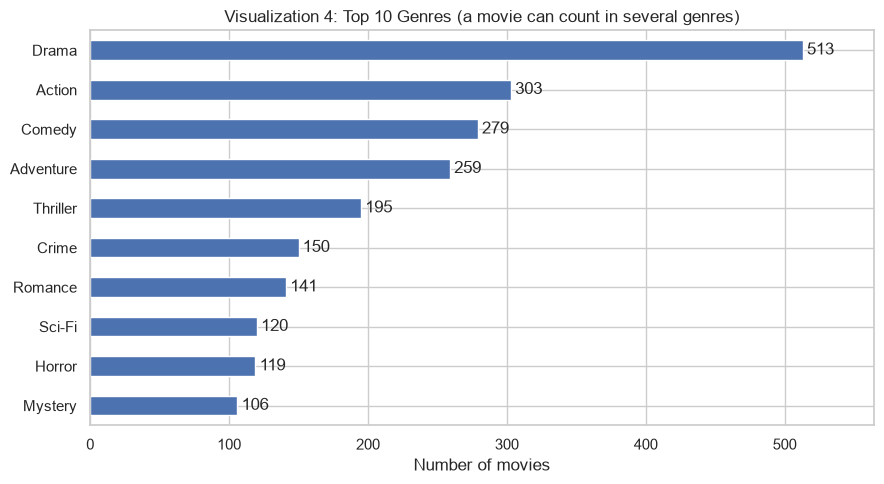

In [243]:
top10 = genres["Genre"].value_counts().head(10)

ax = top10.sort_values().plot(kind="barh", figsize=(9, 5))
ax.bar_label(ax.containers[0], padding=3)
ax.set(title="Visualization 4: Top 10 Genres (a movie can count in several genres)", xlabel="Number of movies", ylabel="")
ax.set_xlim(0, top10.max() * 1.10)
plt.tight_layout()
plt.show()

**Drama** is by far the most common genre (513 movies, over half the dataset), followed by Action (303), Comedy (279), and Adventure (259).
Drama is a broad label that is often combined with other genres. Genre groups therefore **overlap**, which must be kept in mind when comparing them.

#### 3.3 Explore relationships between numerical and categorical attributes.

##### Visualization 5: IMDB Rating by Genre
We compare the six most common genres, plus Horror as a contrast.

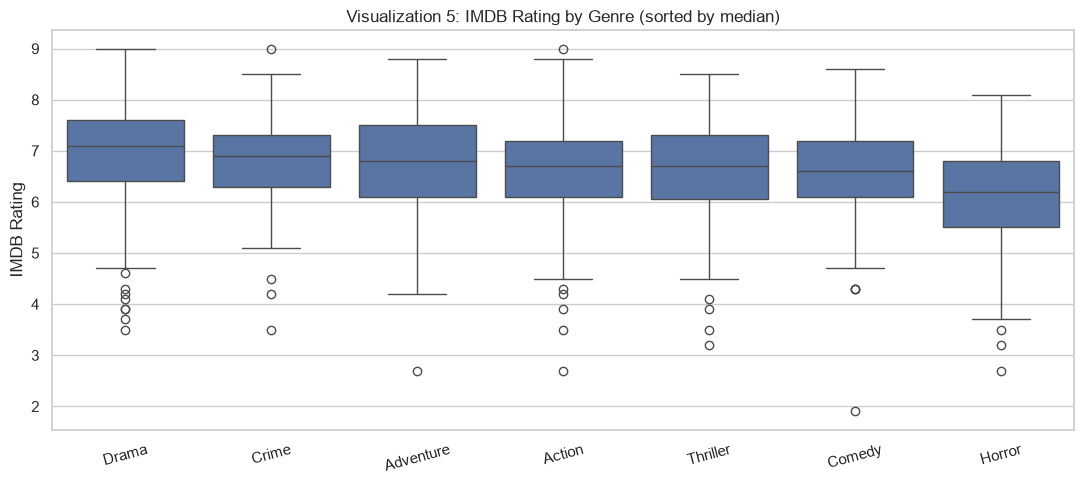

,count,mean,median
Genre,,,
Drama,513,6.95,7.1
Crime,150,6.79,6.9
Adventure,259,6.77,6.8
Action,303,6.61,6.7
Thriller,195,6.59,6.7
Comedy,279,6.65,6.6
Horror,119,6.09,6.2


In [244]:
selected = genres["Genre"].value_counts().head(6).index.tolist() + ["Horror"]
subset = genres[genres["Genre"].isin(selected)]
order = subset.groupby("Genre")["Rating"].median().sort_values(ascending=False).index

plt.figure(figsize=(11, 5))
ax = sns.boxplot(data=subset, x="Genre", y="Rating", order=order)
ax.set(title="Visualization 5: IMDB Rating by Genre (sorted by median)", xlabel="", ylabel="IMDB Rating")
ax.tick_params(axis="x", labelrotation=15)
plt.tight_layout()
plt.show()

subset.groupby("Genre")["Rating"].agg(["count", "mean", "median"]).loc[order].round(2)

**Among the seven plotted genres**, Drama has the highest median rating (7.1) and Horror the lowest (6.2). Action, Comedy, and Thriller sit between 6.6 and 6.7.
Genre is linked to how audiences rate a movie. The 0.9-point gap is a descriptive difference, not a causal effect. Groups overlap, and genres outside this plot can have higher medians.

##### Visualization 6: Median Revenue by Genre
We use the median because revenue is skewed. Only genres with at least 20 movies with real revenue are kept, so very small groups (for example Western, with 5) do not mislead.

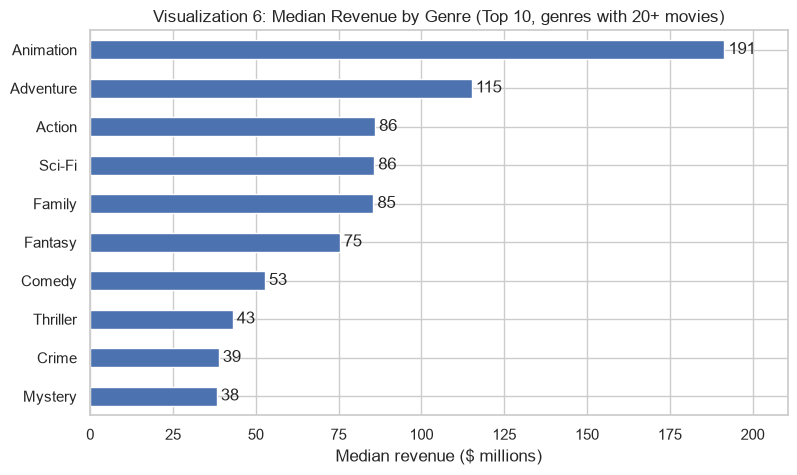

,Movies,Median_Rating,Revenue_Observed,Median_Revenue
Genre,,,,
War,13,7.50,10,28.16
Animation,49,7.40,47,191.45
History,29,7.40,26,33.18
Musical,5,7.40,5,52.88
Biography,81,7.30,75,27.37
Sport,18,7.15,16,43.48
Drama,513,7.10,440,27.20
Music,16,7.00,15,31.66
Western,7,6.90,5,93.38


In [245]:
genre_sizes = genres.dropna(subset=["Revenue_Millions"])["Genre"].value_counts()
median_rev = (genres[genres["Genre"].isin(genre_sizes[genre_sizes >= 20].index)]
              .groupby("Genre")["Revenue_Millions"].median()
              .sort_values(ascending=False).head(10))

ax = median_rev.sort_values().plot(kind="barh", figsize=(9, 5))
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set(title="Visualization 6: Median Revenue by Genre (Top 10, genres with 20+ movies)",
       xlabel="Median revenue ($ millions)", ylabel="")
ax.set_xlim(0, median_rev.max() * 1.1)   # leave room for the labels
plt.show()

genres.groupby("Genre").agg(
    Movies=("Rating", "count"),
    Median_Rating=("Rating", "median"),
    Revenue_Observed=("Revenue_Millions", "count"),
    Median_Revenue=("Revenue_Millions", "median"),
).sort_values("Median_Rating", ascending=False).round(2)

**Animation** earns by far the most (median ≈ $191M), followed by **Adventure** (≈ $115M). Drama, the most common genre and highest-rated among the seven in Visualization 5, is **not in the top 10** (median ≈ $27M).
Drama has lower median revenue than Animation, but this does not show an overall tradeoff between ratings and revenue. Animation also has a higher median rating (7.4 versus 7.1). The preceding table compares all genres; small and overlapping groups need caution.

#### 3.4 Investigate correlations and potential nonlinear relationships.

##### Visualization 7: IMDB Rating vs Metascore

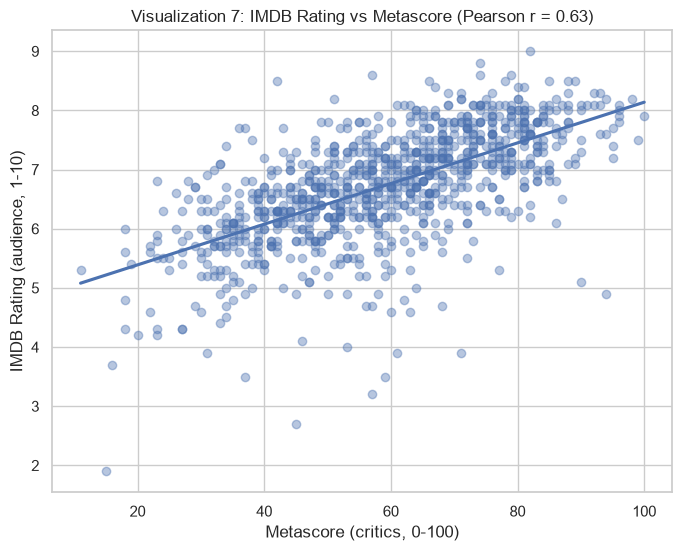

In [246]:
pair = real[["Metascore", "Rating"]].dropna()
r = pair["Metascore"].corr(pair["Rating"], method="pearson")

plt.figure(figsize=(8, 6))
ax = sns.regplot(data=pair, x="Metascore", y="Rating", ci=None, scatter_kws={"alpha": 0.4})
ax.set(title=f"Visualization 7: IMDB Rating vs Metascore (Pearson r = {r:.2f})",
       xlabel="Metascore (critics, 0-100)", ylabel="IMDB Rating (audience, 1-10)")
plt.show()

A **positive, moderately strong** relationship (r = 0.63): movies that critics like tend to be liked by audiences too.
The agreement is far from perfect. The spread around the descriptive line shows that one score does not precisely determine the other, the scores also use different scales.

##### Visualization 8: Votes vs Revenue (log-log scale)
Both variables are heavily skewed, so both axes use a log scale. The single movie with revenue = 0 is left out because log(0) is undefined.

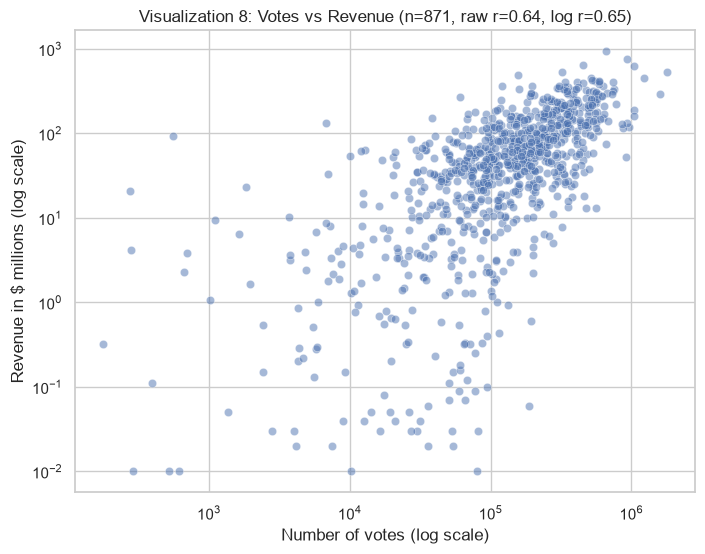

In [247]:
pair = real.loc[real["Revenue_Millions"] > 0, ["Votes", "Revenue_Millions"]].dropna()
r_raw = pair["Votes"].corr(pair["Revenue_Millions"], method="pearson")
r_log = np.log(pair["Votes"]).corr(np.log(pair["Revenue_Millions"]), method="pearson")

plt.figure(figsize=(8, 6))
ax = sns.scatterplot(data=pair, x="Votes", y="Revenue_Millions", alpha=0.5)
ax.set(xscale="log", yscale="log",
       title=f"Visualization 8: Votes vs Revenue (n={len(pair)}, raw r={r_raw:.2f}, log r={r_log:.2f})",
       xlabel="Number of votes (log scale)", ylabel="Revenue in $ millions (log scale)")
plt.show()

Movies with more votes tend to have greater recorded revenue. For the 871 movies with positive observed revenue, Pearson correlation is about **0.64 on the raw values** and **0.65 on the log-transformed values**. The log axes make the wide ranges easier to inspect, but the similar correlations and substantial scatter do not establish a multiplicative relationship or prove nonlinearity. The zero-revenue movie is excluded only from this plot, not from the overall correlation table.

##### Visualization 9: Correlation Heatmap (multivariate)

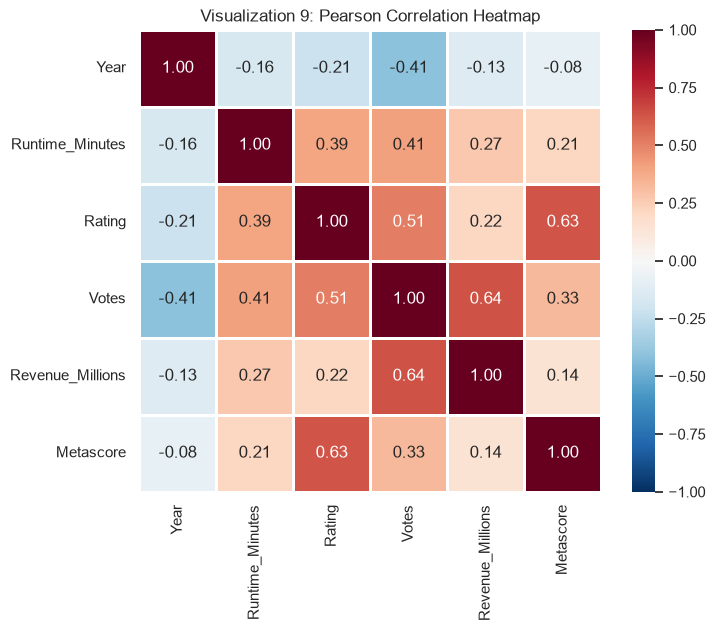

In [248]:
corr_cols = ["Year", "Runtime_Minutes", "Rating", "Votes", "Revenue_Millions", "Metascore"]
corr = real[corr_cols].corr(method="pearson")     # pairwise: each pair uses all its real values

plt.figure(figsize=(8, 6))
ax = sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="RdBu_r", square=True, linewidths=1)
ax.set_title("Visualization 9: Pearson Correlation Heatmap")
plt.show()

The strongest links are **Votes–Revenue (0.64)**, **Rating–Metascore (0.63)**, and **Votes–Rating (0.51)**. **Year** is negatively correlated with Votes (−0.41), which may reflect time available to collect votes and differences in sample composition, the dataset cannot separate these explanations.
Votes is associated with both audience ratings and recorded revenue. Pairwise deletion means different cells can use different numbers of movies, the selected-pair table below reports those counts. Rating and Revenue themselves are only **weakly related (0.22)**, so a well-rated movie is not automatically a high-revenue film.

##### Pearson vs Spearman correlation

- **Pearson** measures *linear* relationships.

- **Spearman** measures any *monotonic* relationship (always rising or always falling, even if not in a straight line).

A difference in their magnitudes can reflect curvature, outliers, ties, or skew. It is a reason to inspect the plot, not a test for nonlinearity.

In [249]:
# Pearson and Spearman follow Lab 01, Topic 3.
pairs = [("Rating", "Metascore"), ("Votes", "Revenue_Millions"), ("Rating", "Votes"),
         ("Runtime_Minutes", "Rating"), ("Runtime_Minutes", "Revenue_Millions"),
         ("Rating", "Revenue_Millions"), ("Year", "Votes")]

rows = []
for a, b in pairs:
    d = real[[a, b]].dropna()
    pearson_r = d[a].corr(d[b], method="pearson")
    spearman_r = d[a].corr(d[b], method="spearman")
    rows.append([f"{a} vs {b}", len(d), pearson_r, spearman_r])

corr_table = pd.DataFrame(rows, columns=["Pair", "n", "Pearson r", "Spearman rho"])
corr_table.round(3)

,Pair,n,Pearson r,Spearman rho
0,Rating vs Metascore,936,0.632,0.665
1,Votes vs Revenue_Millions,872,0.640,0.701
2,Rating vs Votes,1000,0.512,0.520
3,Runtime_Minutes vs Rating,1000,0.392,0.383
4,Runtime_Minutes vs Revenue_Millions,872,0.268,0.247
5,Rating vs Revenue_Millions,872,0.218,0.159
6,Year vs Votes,1000,-0.412,-0.610


1. **Rating vs Metascore (0.63)** and **Votes vs Revenue (0.64)** are the strongest Pearson relationships among these pairs.
2. **Year vs Votes** has a stronger rank association (Spearman −0.61) than linear association (Pearson −0.41). Visualization 10 shows how the median votes vary by year, including the sharp decline in the last two years.
3. **Votes vs Revenue** has Spearman 0.70 versus Pearson 0.64. Skew and extreme values may contribute to the difference, it does not prove a nonlinear relationship.
4. **Runtime vs Rating (0.39)** is positive: longer movies tend to have higher ratings in this sample.
5. **Rating vs Revenue (0.22)** is weak: audience rating alone says little about recorded revenue.

These are descriptive associations in a selected sample. No causal conclusion or population-level significance claim is made.

#### 3.5 Identify unusual patterns, trends, or differences between meaningful subgroups.

##### Visualization 10: Trends Over Time
Three separate panels show sample counts, mean ratings, and median votes by release year.

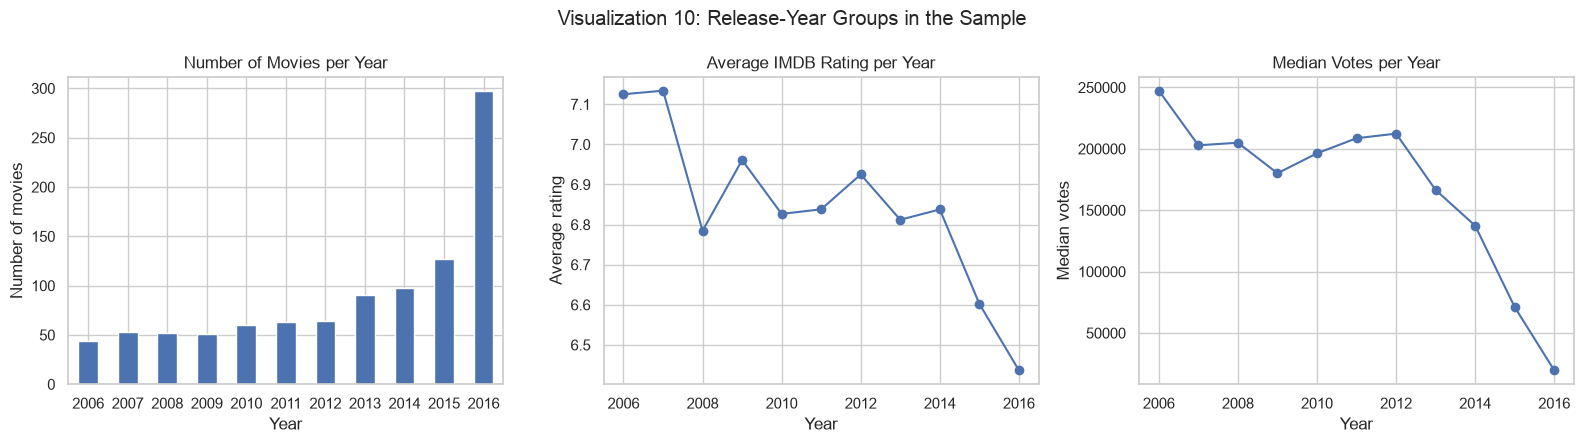

Year,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016
Movies,44.00,53.00,52.00,51.00,60.00,63.00,64.00,91.00,98.00,127.0,297.00
Avg_Rating,7.12,7.13,6.78,6.96,6.83,6.84,6.92,6.81,6.84,6.6,6.44
Median_Votes,247361.50,202890.00,204944.50,180105.00,196320.00,208632.00,212364.50,166512.00,137433.50,71149.0,19660.00


In [250]:
by_year = real.groupby("Year").agg(Movies=("Title", "count"), Avg_Rating=("Rating", "mean"), Median_Votes=("Votes", "median"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
by_year["Movies"].plot(kind="bar", ax=axes[0], rot=0)
axes[0].set(title="Number of Movies per Year", xlabel="Year", ylabel="Number of movies")
by_year["Avg_Rating"].plot(marker="o", ax=axes[1])
axes[1].set(title="Average IMDB Rating per Year", xlabel="Year", ylabel="Average rating")
by_year["Median_Votes"].plot(marker="o", ax=axes[2])
axes[2].set(title="Median Votes per Year", xlabel="Year", ylabel="Median votes")
plt.suptitle("Visualization 10: Release-Year Groups in the Sample")
plt.tight_layout()
plt.show()

by_year.round(2).T

The number of movies **rises sharply** after 2012 (297 in 2016), while the average rating **falls** from about 7.1 (2006 – 2007) to 6.44 (2016). Median votes drop from about 247k (2006) to 20k (2016).
Selection and time available to collect votes are possible explanations. The sampling method and collection date are unknown. This is a comparison of release-year groups at one data snapshot, not repeated measurement of the same films, and cannot establish a decline in film quality.

**Unusual patterns and subgroup differences found:**

| # | Finding | Evidence |
|---|---|---|
| 1 | Horror is the lowest-rated genre | Median 6.2 vs 7.1 for Drama (Vis. 5) |
| 2 | Drama and Animation differ in ratings and revenue | Drama: median rating 7.1, revenue $27M, Animation: 7.4, $191M (Vis. 6 table) |
| 3 | Missing revenue is concentrated in low-vote, recent films | 31% missing in 2016, ~4.7k vs ~135k median votes (2.1.1) |
| 4 | Votes are associated with release year | Spearman −0.61 vs Pearson −0.41 (3.4) |
| 5 | Average rating declines over time | 7.12 (2006) → 6.44 (2016) (Vis. 10) |
| 6 | Extreme earnings inequality | Top movie $937M vs median $48M (Vis. 3) |

#### 3.6 Produce at least eight informative visualizations, using suitable chart types.
Ten visualizations were produced, each followed by an interpretation of what it reveals and why it is relevant.

| # | Visualization | Chart type | Analysis type | Key finding |
|---|---|---|---|---|
| 1 | IMDB Rating | Histogram + KDE | Univariate | Peak near 7, left-skewed |
| 2 | Runtime | Boxplot | Univariate | Median 111 min, outliers only on the long side |
| 3 | Revenue | Histogram (original vs log) | Univariate | Extreme right skew, balanced after log |
| 4 | Top 10 Genres | Horizontal bar | Univariate (categorical) | Drama in over half of all movies |
| 5 | Rating by Genre | Boxplot | Bivariate (cat. × num.) | Drama highest among seven plotted genres, Horror lowest |
| 6 | Median Revenue by Genre | Horizontal bar | Bivariate (cat. × num.) | Animation and Adventure earn the most |
| 7 | Rating vs Metascore | Scatter + regression line | Bivariate (num. × num.) | r = 0.63: critics and audiences mostly agree |
| 8 | Votes vs Revenue | Scatter (log-log) | Bivariate (num. × num.) | Raw r = 0.64, log r = 0.65, positive association |
| 9 | Correlation Heatmap | Heatmap | Multivariate | Votes associated with ratings and revenue |
| 10 | Trends Over Time | Bar + line | Bivariate (temporal) | More movies, lower average rating over time |

### Summary of Key Findings

1. Votes is positively associated with Rating (0.51) and observed Revenue (0.64).
2. Audience Rating and Metascore are positively associated (0.63), with substantial variation between individual movies.
3. Drama has the highest median rating among the seven genres plotted in Visualization 5. Across all genres, several have higher medians, including Animation (7.4), which also leads median revenue among genres with at least 20 observed revenue values.
4. Horror has the lowest median rating across the listed genres (6.2). Genre groups overlap and differ in size.
5. Revenue is strongly right-skewed: its observed median is about 48M, compared with a maximum of 937M in the assumed currency.
6. Newer release-year groups have fewer votes and lower mean ratings. Selection and exposure time are possible explanations, not demonstrated causes.
7. Missing revenue is more common among 2016 films and films with fewer votes. Revenue findings describe the observed-revenue subset and may not generalize to the missing group.

---
## Task 4: Documentation and Reproducibility (5 Marks)
Submit:

1. **Jupyter Notebook (.ipynb)** containing organized, executable code, headings, comments, analysis, and interpretations.
2. **Analytical Report (PDF, 5–8 pages)** summarizing the your findings/visualizations, results, etc.
3. **Cleaned Dataset (CSV)** and a concise record of preprocessing changes.

Code should be clearly organized, and all visualizations and analytical results should be reproducible.

### Solution – Task 4

#### 4.1 Google Colab Link

**Google Colab:** [Open notebook](https://colab.research.google.com/drive/11gFMitot8_iTQSB2DfHgg0diwHXKbRWF?usp=sharing)

#### 4.2 GitHub Repository Link

**GitHub Repository:** [View Repository](https://github.com/SaeedAlbarhami/CSPG730-IMDB-EDA)

#### 4.3 Reproducibility Steps

1. Open the notebook in Google Colab or locally in Jupyter.
2. Install dependencies if needed: `pip install pandas numpy matplotlib seaborn scipy scikit-learn`.
3. Restart the runtime/kernel and run all cells from top to bottom.
4. The notebook uses `data/imdb_movie_dataset.csv` when available, otherwise reads it from GitHub, and saves `data/imdb_cleaned.csv`.

For Google Colab setup, see `README.md`. Package versions are printed below; preprocessing changes are recorded in Section 2.6.3.

In [251]:
import sys
from importlib.metadata import version

print("Python:", sys.version.split()[0])
for package in ["pandas", "numpy", "matplotlib", "seaborn", "scipy", "scikit-learn"]:
    print(f"{package}: {version(package)}")

Python: 3.12.15
pandas: 2.2.3
numpy: 2.5.4
matplotlib: 3.11.2
seaborn: 0.13.2
scipy: 1.18.1
scikit-learn: 1.9.1
